# Synthetic Emoji CNN Classification

Portfolio edition: Behrad Mazaheri. Template/source credit: Mohammad Amanlou.

**Static review only — not rerun.** Outputs below are retained from `EmojiClassification.ipynb`, including failures or missing executions. They do not validate later revisions. Read README and REVIEW before running cells or citing metrics. Source cell references use zero-based indices before this added banner.


<div align="center">
    <img src="https://www.sharif.ir/documents/20124/0/logo-fa-IR.png/4d9b72bc-494b-ed5a-d3bb-e7dfd319aec8?t=1609608338755" alt="Logo" width="200">
    <p><b>HW2 @ Deep Learning Course, Dr. Soleymani</b></p>
    <p><b>Desinged by Mohammad Amanlou</b></p>
</div>

---




*Full Name:* behrad mazaheri

*Student Number:* [student ID removed]

# تمرین CNN — «آزمایشگاه حال‌سنجی ایموجی‌ها»
## نسخه‌ی پاسخ‌دار برای طراح تمرین

در این پروژه قرار است یک **CNN از صفر** برای تشخیص حالت چهره‌ی ایموجی‌ها بسازیم.  
ایده‌ی پروژه این است که یک ربات بامزه باید از روی تصویر ایموجی‌ها تشخیص بدهد که حال آن‌ها چیست:

- `happy`
- `sad`
- `angry`
- `surprised`
- `sleepy`

## داستان پروژه
در شهر ایموجی‌ها، یک ربات کوچک وظیفه دارد پیام‌های تصویری را مرتب‌سازی کند.  
اما ایموجی‌ها همیشه تمیز و واضح نیستند: گاهی کمی چرخیده‌اند، گاهی نویز دارند، گاهی جابه‌جا شده‌اند.  
هدف شما این است که یک مدل CNN طراحی کنید که در چنین شرایطی هم بتواند حالت چهره را درست تشخیص دهد.

## بعد از انجام این نوت‌بوک باید بتوانید:
1. یک دیتاست تصویری را بسازید یا بارگذاری کنید.
2. روی داده‌ها **EDA** ساده انجام دهید.
3. **Data Augmentation** مناسب برای مسئله‌ی تصویری انتخاب کنید.
4. یک **CNN پایه** را از صفر پیاده‌سازی و آموزش دهید.
5. با استفاده از **loss curve**، **accuracy**، **macro F1** و **confusion matrix** مدل را تحلیل کنید.
6. خطاهای مدل را بررسی کنید و یک نسخه‌ی بهبود‌یافته از مدل ارائه دهید.

## بخش ۰ — کتابخانه‌ها و تنظیمات اولیه

### خروجی مورد انتظار
- چاپ دستگاه اجرا
- چاپ نام کلاس‌ها

In [1]:
import math
import random
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from PIL import Image, ImageDraw, ImageFilter, ImageOps, ImageEnhance

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMG_SIZE = 64
BATCH_SIZE = 64
NUM_CLASSES = 5
CLASS_NAMES = ["happy", "sad", "angry", "surprised", "sleepy"]

# TODO:
print(f"Device: {device}")
print(f"Classes: {CLASS_NAMES}")

Device: cuda
Classes: ['happy', 'sad', 'angry', 'surprised', 'sleepy']


## بخش ۱ — ساخت دیتاست مصنوعی ایموجی‌ها

In [2]:
def _jitter(rng, low, high):
    return rng.randint(low, high)

def add_soft_noise(img, rng, amount=35):
    arr = np.array(img).astype(np.int16)
    noise = rng.normalvariate(0, 1)
    gaussian = np.random.default_rng(rng.randint(0, 10_000)).normal(0, amount, size=arr.shape)
    arr = np.clip(arr + gaussian, 0, 255).astype(np.uint8)
    return Image.fromarray(arr)

def draw_emoji(label, img_size=64, seed=0, hard_mode=False):
    rng = random.Random(seed)

    bg_color = (
        245 + _jitter(rng, -8, 8),
        245 + _jitter(rng, -8, 8),
        250 + _jitter(rng, -8, 5),
    )
    img = Image.new("RGB", (img_size, img_size), bg_color)
    draw = ImageDraw.Draw(img)

    # background dots
    for _ in range(40 if not hard_mode else 70):
        x = _jitter(rng, 0, img_size - 1)
        y = _jitter(rng, 0, img_size - 1)
        r = _jitter(rng, 1, 2)
        c = 235 + _jitter(rng, -18, 12)
        draw.ellipse((x-r, y-r, x+r, y+r), fill=(c, c, c + _jitter(rng, -5, 5)))

    cx = img_size // 2 + _jitter(rng, -3, 3)
    cy = img_size // 2 + _jitter(rng, -3, 3)
    radius = 22 + _jitter(rng, -2, 2)

    draw.ellipse(
        (cx - radius, cy - radius, cx + radius, cy + radius),
        fill=(252, 215 + _jitter(rng, -12, 8), 70 + _jitter(rng, -10, 8)),
        outline=(120, 90, 20),
        width=2,
    )

    if rng.random() < 0.55:
        cheek_color = (245, 165 + _jitter(rng, -10, 10), 165 + _jitter(rng, -10, 10))
        draw.ellipse((cx - 16, cy + 2, cx - 10, cy + 8), fill=cheek_color)
        draw.ellipse((cx + 10, cy + 2, cx + 16, cy + 8), fill=cheek_color)

    ex = 9 + _jitter(rng, -1, 1)
    ey = 8 + _jitter(rng, -1, 1)

    left_eye = (cx - ex, cy - ey)
    right_eye = (cx + ex, cy - ey)

    def draw_open_eye(center, w=4, h=5):
        x, y = center
        draw.ellipse((x - w//2, y - h//2, x + w//2, y + h//2), fill=(20, 20, 20))

    def draw_closed_eye(center, width=6):
        x, y = center
        draw.line((x - width//2, y, x + width//2, y), fill=(20, 20, 20), width=2)

    def draw_arc_eye(center, start, end, width=2):
        x, y = center
        box = (x - 4, y - 4, x + 4, y + 4)
        draw.arc(box, start=start, end=end, fill=(20, 20, 20), width=width)

    if label == "angry":
        draw.line((left_eye[0] - 5, left_eye[1] - 6, left_eye[0] + 2, left_eye[1] - 8), fill=(80, 40, 10), width=2)
        draw.line((right_eye[0] - 2, right_eye[1] - 8, right_eye[0] + 5, right_eye[1] - 6), fill=(80, 40, 10), width=2)
    elif label == "sad":
        draw.line((left_eye[0] - 5, left_eye[1] - 8, left_eye[0] + 2, left_eye[1] - 6), fill=(80, 40, 10), width=2)
        draw.line((right_eye[0] - 2, right_eye[1] - 6, right_eye[0] + 5, right_eye[1] - 8), fill=(80, 40, 10), width=2)
    elif label == "surprised":
        draw.line((left_eye[0] - 4, left_eye[1] - 8, left_eye[0] + 4, left_eye[1] - 8), fill=(90, 50, 10), width=2)
        draw.line((right_eye[0] - 4, right_eye[1] - 8, right_eye[0] + 4, right_eye[1] - 8), fill=(90, 50, 10), width=2)

    if label == "happy":
        draw_arc_eye(left_eye, 10, 170, width=2)
        draw_arc_eye(right_eye, 10, 170, width=2)
        draw.arc((cx - 11, cy - 1, cx + 11, cy + 15), start=15, end=165, fill=(120, 30, 30), width=3)

    elif label == "sad":
        draw_open_eye(left_eye, 3, 5)
        draw_open_eye(right_eye, 3, 5)
        draw.arc((cx - 11, cy + 8, cx + 11, cy + 20), start=200, end=340, fill=(120, 30, 30), width=3)
        if rng.random() < 0.65:
            # a tear
            tx = left_eye[0] - 2
            ty = left_eye[1] + 6
            draw.ellipse((tx - 2, ty, tx + 2, ty + 6), fill=(100, 180, 255))

    elif label == "angry":
        draw_open_eye(left_eye, 3, 5)
        draw_open_eye(right_eye, 3, 5)
        draw.arc((cx - 10, cy + 7, cx + 10, cy + 19), start=200, end=340, fill=(120, 10, 10), width=3)

    elif label == "surprised":
        draw_open_eye(left_eye, 4, 6)
        draw_open_eye(right_eye, 4, 6)
        mouth_r = 5 + _jitter(rng, -1, 1)
        draw.ellipse((cx - mouth_r, cy + 6, cx + mouth_r, cy + 6 + 2*mouth_r), outline=(120, 30, 30), width=3)

    elif label == "sleepy":
        draw_closed_eye(left_eye, width=7)
        draw_closed_eye(right_eye, width=7)
        draw.arc((cx - 10, cy + 6, cx + 10, cy + 12), start=5, end=175, fill=(120, 30, 30), width=2)
        if rng.random() < 0.5:
            bx = right_eye[0] + 5
            by = right_eye[1] - 2
            draw.ellipse((bx, by, bx + 5, by + 5), outline=(120, 180, 255), width=2)

    if hard_mode and rng.random() < 0.45:
        y0 = cy + _jitter(rng, -3, 6)
        draw.rectangle((cx - 14, y0, cx + 14, y0 + 3), fill=(230, 230, 230))

    img = img.rotate(_jitter(rng, -10, 10) if not hard_mode else _jitter(rng, -18, 18), fillcolor=bg_color)

    if rng.random() < (0.4 if not hard_mode else 0.75):
        img = add_soft_noise(img, rng, amount=14 if not hard_mode else 24)

    if hard_mode and rng.random() < 0.3:
        img = img.filter(ImageFilter.GaussianBlur(radius=0.7))

    return img

## بخش ۲ — مشاهده‌ی نمونه‌ها و بررسی اولیه‌ی داده

### صورت سؤال
1. از هر کلاس چند نمونه تصویر نمایش دهید.
2. درباره‌ی تفاوت‌های ظاهری کلاس‌ها توضیح کوتاه بنویسید.
3. تعداد نمونه‌های هر کلاس در هر split را مشخص کنید.
4. یک نمودار میله‌ای از توزیع داده‌ها رسم کنید.

### خروجی مورد انتظار
- یک grid از نمونه‌تصاویر
- جدول یا نمودار تعداد نمونه‌ها

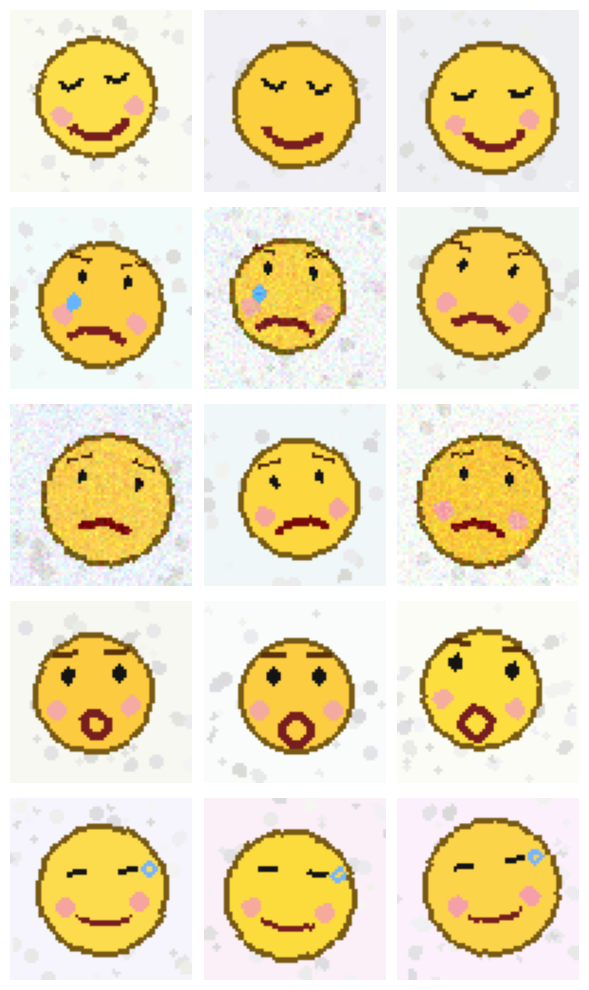

In [3]:
def show_samples_per_class(class_names, samples_per_class=3, hard_mode=False):
    # TODO:
    fig, axes = plt.subplots(len(class_names), samples_per_class, figsize=(samples_per_class * 2, len(class_names) * 2))
    for class_idx, class_name in enumerate(class_names):
        for sample_idx in range(samples_per_class):
            img = draw_emoji(class_name, img_size=IMG_SIZE, seed=class_idx * 100 + sample_idx, hard_mode=hard_mode)
            ax = axes[class_idx, sample_idx] if len(class_names) > 1 else axes[sample_idx]
            ax.imshow(img)
            if sample_idx == 0:
                ax.set_ylabel(class_name, fontsize=12)
            ax.axis('off')
    plt.tight_layout()
    plt.show()

show_samples_per_class(CLASS_NAMES, samples_per_class=3)

,split,label_name,label_idx,seed,hard_mode
0,train,sad,1,10046,False
1,train,surprised,3,30059,False
2,train,happy,0,37,False
3,train,sad,1,10029,False
4,train,happy,0,32,False


,split,label_name,count
0,test,angry,20
1,test,happy,20
2,test,sad,20
3,test,sleepy,20
4,test,surprised,20
5,train,angry,60
6,train,happy,60
7,train,sad,60
8,train,sleepy,60
9,train,surprised,60


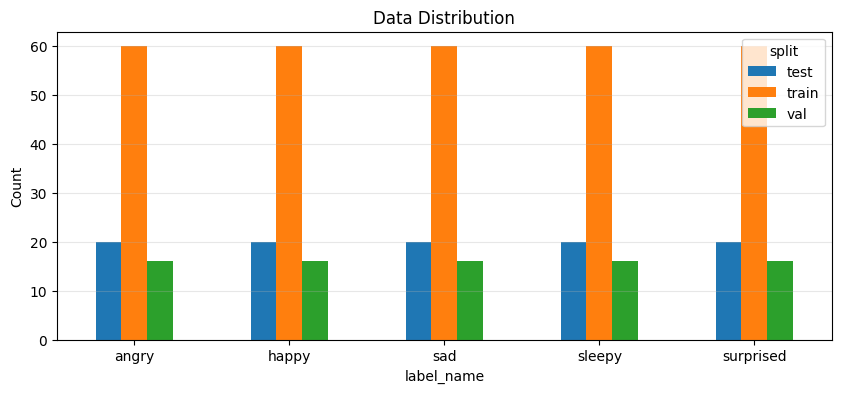

In [4]:
SPLIT_COUNTS = {
    "train": 300,
    "val": 80,
    "test": 100,
}

def build_records(split_name, class_names, counts_per_class, hard_mode=False, seed_offset=0):
    records = []
    label_to_idx = {name: i for i, name in enumerate(class_names)}
    for class_name in class_names:
        label_idx = label_to_idx[class_name]
        for i in range(counts_per_class):
            records.append({
                "split": split_name,
                "label_name": class_name,
                "label_idx": label_idx,
                "seed": seed_offset + 10_000 * label_idx + i,
                "hard_mode": hard_mode,
            })
    random.Random(SEED + seed_offset).shuffle(records)
    return records

# TODO:
train_records = build_records("train", CLASS_NAMES, SPLIT_COUNTS["train"] // NUM_CLASSES, hard_mode=False, seed_offset=0)
val_records   = build_records("val", CLASS_NAMES, SPLIT_COUNTS["val"] // NUM_CLASSES, hard_mode=False, seed_offset=1)
test_records  = build_records("test", CLASS_NAMES, SPLIT_COUNTS["test"] // NUM_CLASSES, hard_mode=True, seed_offset=2)

all_records = pd.DataFrame(train_records + val_records + test_records)
display(all_records.head())

count_df = all_records.groupby(["split", "label_name"]).size().reset_index(name="count")
display(count_df)

# TODO: جدول یا نمودار تعداد نمونه‌ها
count_df.pivot(index="label_name", columns="split", values="count").plot(kind="bar", figsize=(10, 4))
plt.ylabel("Count")
plt.title("Data Distribution")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.show()

## بخش ۳ — پیش‌پردازش و Data Augmentation

### صورت سؤال
1. برای داده‌های آموزشی یک pipeline مناسب از augmentation تعریف کنید.
2. برای داده‌های اعتبارسنجی و تست فقط پیش‌پردازش‌های ضروری را اعمال کنید.
3. توضیح دهید چرا در این مسئله این تبدیلات مناسب‌اند.

### پیشنهاد
برای train می‌توانید از موارد زیر استفاده کنید:
- `RandomRotation`
- `RandomResizedCrop`
- `ColorJitter`
- `RandomHorizontalFlip`

### خروجی مورد انتظار
- تعریف transformهای train / val / test
- نمایش یک نمونه تصویر قبل و بعد از augmentation

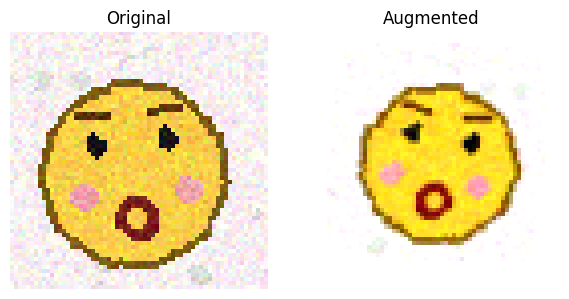

In [5]:
class Compose:
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, img):
        # TODO
        for t in self.transforms:
            img = t(img)
        return img

class Resize:
    def __init__(self, size):
        if isinstance(size, int):
            size = (size, size)
        self.size = size

    def __call__(self, img):
        # TODO
        return img.resize(self.size, Image.Resampling.BILINEAR)

class RandomHorizontalFlip:
    def __init__(self, p=0.5):
        self.p = p

    def __call__(self, img):
        # TODO
        if random.random() < self.p:
            return img.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
        return img

class RandomRotation:
    def __init__(self, degrees):
        self.degrees = degrees

    def __call__(self, img):
        # TODO
        angle = random.uniform(-self.degrees, self.degrees)
        return img.rotate(angle, fillcolor=(245, 245, 250))

class RandomResizedCrop:
    def __init__(self, size, scale=(0.85, 1.0)):
        self.size = (size, size) if isinstance(size, int) else size
        self.scale = scale

    def __call__(self, img):
        # TODO
        scale_factor = random.uniform(self.scale[0], self.scale[1])
        new_size = (int(self.size[0] * scale_factor), int(self.size[1] * scale_factor))
        cropped = img.resize(new_size, Image.Resampling.BILINEAR)
        
        left = random.randint(0, self.size[0] - new_size[0])
        top = random.randint(0, self.size[1] - new_size[1])
        
        padded = Image.new("RGB", self.size, (245, 245, 250))
        padded.paste(cropped, (left, top))
        return padded

class ColorJitter:
    def __init__(self, brightness=0.0, contrast=0.0, saturation=0.0):
        self.brightness = brightness
        self.contrast = contrast
        self.saturation = saturation

    def __call__(self, img):
        # TODO
        if self.brightness > 0:
            factor = random.uniform(1 - self.brightness, 1 + self.brightness)
            img = ImageEnhance.Brightness(img).enhance(factor)
        if self.contrast > 0:
            factor = random.uniform(1 - self.contrast, 1 + self.contrast)
            img = ImageEnhance.Contrast(img).enhance(factor)
        if self.saturation > 0:
            factor = random.uniform(1 - self.saturation, 1 + self.saturation)
            img = ImageEnhance.Color(img).enhance(factor)
        return img

class ToTensorNormalize:
    def __init__(self, mean, std):
        self.mean = np.array(mean, dtype=np.float32).reshape(3, 1, 1)
        self.std = np.array(std, dtype=np.float32).reshape(3, 1, 1)

    def __call__(self, img):
        # TODO
        arr = np.array(img, dtype=np.float32) / 255.0
        arr = np.transpose(arr, (2, 0, 1))
        arr = (arr - self.mean) / self.std
        return torch.from_numpy(arr).float()

# TODO
train_transform = Compose([
    RandomRotation(degrees=15),
    RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),
    RandomHorizontalFlip(p=0.5),
    ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    ToTensorNormalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

eval_transform = Compose([
    Resize(IMG_SIZE),    
    ToTensorNormalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

def denormalize(t):
    t = t.clone().cpu()
    for c in range(3):
        t[c] = t[c] * 0.5 + 0.5
    return t.clamp(0, 1)

sample_img = draw_emoji("surprised", img_size=IMG_SIZE, seed=1234)
augmented = train_transform(sample_img)

# TODO: نمایش یک نمونه تصویر قبل و بعد
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(sample_img)
axes[0].set_title("Original")
axes[0].axis('off')

aug_img = np.transpose(denormalize(augmented).numpy(), (1, 2, 0))
axes[1].imshow(aug_img)
axes[1].set_title("Augmented")
axes[1].axis('off')
plt.tight_layout()
plt.show()

## بخش ۴ — ساخت Dataset و DataLoader

### صورت سؤال
1. برای train / val / test سه DataLoader ایجاد کنید.
2. یک batch را نمایش دهید و shape داده‌ها و برچسب‌ها را چاپ کنید.

### خروجی مورد انتظار
- سه dataloader
- نمایش یک batch نمونه

In [6]:
class EmojiMoodDataset(Dataset):
    def __init__(self, records, transform=None):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = draw_emoji(
            rec["label_name"],
            img_size=IMG_SIZE,
            seed=rec["seed"],
            hard_mode=rec["hard_mode"],
        )
        if self.transform is not None:
            img = self.transform(img)
        label = rec["label_idx"]
        return img, label

# TODO
train_dataset = EmojiMoodDataset(train_records, transform=train_transform)
val_dataset   = EmojiMoodDataset(val_records, transform=eval_transform)
test_dataset  = EmojiMoodDataset(test_records, transform=eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([64, 3, 64, 64])
Batch label shape: torch.Size([64])


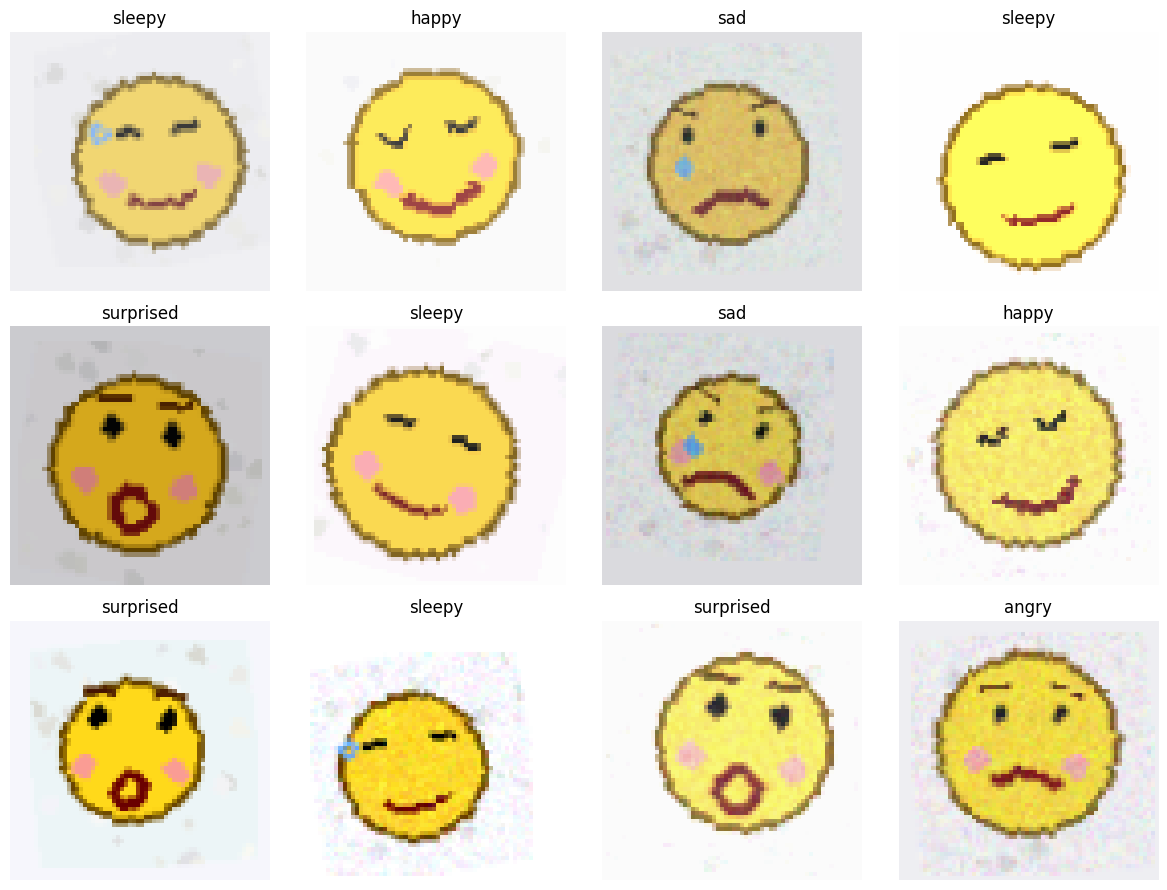

In [7]:
def show_batch(images, labels, class_names, max_items=12):
    # TODO
    n_show = min(max_items, len(images))
    cols = 4
    rows = math.ceil(n_show / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
    axes = np.array(axes).reshape(rows, cols)
    
    for ax in axes.ravel():
        ax.axis('off')
    
    for i in range(n_show):
        img = np.transpose(denormalize(images[i]).numpy(), (1, 2, 0))
        ax = axes.ravel()[i]
        ax.imshow(img)
        ax.set_title(class_names[labels[i]])
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

show_batch(images, labels, CLASS_NAMES)

## بخش ۵ — طراحی CNN پایه

### صورت سؤال
یک CNN پایه از صفر طراحی کنید که:
1. حداقل 3 بلوک کانولوشنی داشته باشد.
2. در انتها برای طبقه‌بندی از fully connected layers استفاده کند.
3. برای جلوگیری از overfitting از dropout استفاده کند.

### کارهای لازم
- مدل را پیاده‌سازی کنید.
- summary ساده‌ای از تعداد پارامترها گزارش کنید.
- یک forward pass آزمایشی انجام دهید.

### خروجی مورد انتظار
- تعریف مدل
- تعداد پارامترهای قابل آموزش
- shape خروجی مدل برای یک batch نمونه

In [8]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        
        # TODO
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        
        self.fc = nn.Sequential(
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        # TODO
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

# TODO
baseline_model = BaselineCNN(NUM_CLASSES).to(device)

def count_trainable_params(model):
    # TODO
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(baseline_model)
print(f"Trainable params: {count_trainable_params(baseline_model):,}")

# TODO: شکل خروجی مدل
test_input = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)
test_output = baseline_model(test_input)
print(f"Output shape for batch of 2: {test_output.shape}")

BaselineCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Linear(in_features=8192, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=256, out_features=5, bias=True)
  )
)
Trainable params: 2,191,941
Output shape for batch of 2: torch.Size([2, 5])


## بخش ۶ — توابع آموزش و ارزیابی

### صورت سؤال
توابع زیر را پیاده‌سازی کنید:
1. `train_one_epoch`
2. `evaluate_one_epoch`
3. یک حلقه‌ی آموزشی کامل که:
   - loss و accuracy را ذخیره کند
   - بهترین مدل را بر اساس validation loss نگه دارد

### نکته
در این تمرین از:
- `CrossEntropyLoss`
- بهینه‌ساز `Adam`

استفاده می‌کنیم.

### خروجی مورد انتظار
- توابع عمومی آموزش و ارزیابی

In [9]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    # TODO
    model.train()
    total_loss = 0.0
    total_acc = 0.0
    total_samples = 0
    
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * len(labels)
        preds = outputs.argmax(dim=1)
        total_acc += (preds == labels).sum().item()
        total_samples += len(labels)
    
    epoch_loss = total_loss / total_samples
    epoch_acc = total_acc / total_samples
    return epoch_loss, epoch_acc

@torch.no_grad()
def evaluate_one_epoch(model, loader, criterion, device):
    # TODO
    model.eval()
    total_loss = 0.0
    total_acc = 0.0
    total_samples = 0
    
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        total_loss += loss.item() * len(labels)
        preds = outputs.argmax(dim=1)
        total_acc += (preds == labels).sum().item()
        total_samples += len(labels)
    
    epoch_loss = total_loss / total_samples
    epoch_acc = total_acc / total_samples
    return epoch_loss, epoch_acc

def fit_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=8,
    patience=3
):
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
    }

    best_state = deepcopy(model.state_dict())
    best_val_loss = float("inf")
    wait = 0

    for epoch in range(1, epochs + 1):
        # TODO: فاز آموزش و ارزیابی را انجام دهید
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_one_epoch(model, val_loader, criterion, device)
        
        # TODO: خروجی توابع را در تاریخچه ثبت کنید
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch:02d} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping triggered.")
                break

    model.load_state_dict(best_state)
    return history

## بخش ۷ — آموزش مدل پایه

### صورت سؤال
1. criterion و optimizer را تعریف کنید.
2. مدل پایه را برای چند epoch آموزش دهید.
3. تاریخچه‌ی آموزش را ذخیره کنید.
4. در پایان، بهترین نسخه‌ی مدل را نگه دارید.

### خروجی مورد انتظار
- لاگ آموزش در هر epoch

In [10]:
# TODO
baseline_model = BaselineCNN(NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=0.001)

baseline_history = fit_model(baseline_model, train_loader, val_loader, criterion, optimizer, device, epochs=8, patience=3)

Epoch 01 | train_loss=1.6220 train_acc=0.1933 | val_loss=1.5984 val_acc=0.3500
Epoch 02 | train_loss=1.5851 train_acc=0.2900 | val_loss=1.5563 val_acc=0.2000
Epoch 03 | train_loss=1.5473 train_acc=0.3067 | val_loss=1.3805 val_acc=0.5500
Epoch 04 | train_loss=1.3868 train_acc=0.4567 | val_loss=1.0942 val_acc=0.7375
Epoch 05 | train_loss=1.2549 train_acc=0.4967 | val_loss=0.7820 val_acc=0.7750
Epoch 06 | train_loss=1.0578 train_acc=0.5867 | val_loss=0.6041 val_acc=0.8500
Epoch 07 | train_loss=0.8644 train_acc=0.6500 | val_loss=0.5595 val_acc=0.7375
Epoch 08 | train_loss=0.7286 train_acc=0.7000 | val_loss=0.3354 val_acc=0.9625


## بخش ۸ — رسم نمودارهای آموزش

### صورت سؤال
1. نمودار `train/val loss` را رسم کنید.
2. نمودار `train/val accuracy` را رسم کنید.
3. توضیح دهید آیا نشانه‌ای از overfitting یا underfitting مشاهده می‌شود یا خیر.

### خروجی مورد انتظار
- دو نمودار

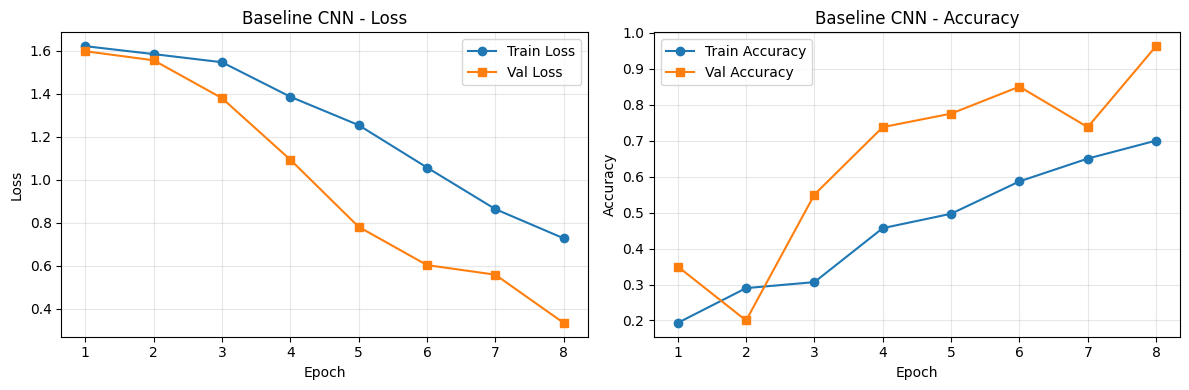

In [11]:
def plot_history(history, title_prefix="Model"):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # TODO
    axes[0].plot(epochs, history["train_loss"], label="Train Loss", marker='o')
    axes[0].plot(epochs, history["val_loss"], label="Val Loss", marker='s')
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"{title_prefix} - Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    axes[1].plot(epochs, history["train_acc"], label="Train Accuracy", marker='o')
    axes[1].plot(epochs, history["val_acc"], label="Val Accuracy", marker='s')
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_title(f"{title_prefix} - Accuracy")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(baseline_history, title_prefix="Baseline CNN")

## بخش ۹ — ارزیابی نهایی روی داده‌ی تست

### صورت سؤال
1. مدل را روی test set ارزیابی کنید.
2. معیارهای زیر را گزارش کنید:
   - Accuracy
   - Precision (macro)
   - Recall (macro)
   - F1-score (macro)
3. یک **Confusion Matrix** رسم کنید.
4. نتیجه را تفسیر کنید: کدام کلاس‌ها بیشتر با هم اشتباه می‌شوند؟

### خروجی مورد انتظار
- metricها
- confusion matrix
- classification report

Baseline Test Accuracy : 0.8400
Baseline Test Precision: 0.8335
Baseline Test Recall   : 0.8400
Baseline Test F1-score : 0.8282

Classification report:
              precision    recall  f1-score   support

       happy       0.80      1.00      0.89        20
         sad       0.77      0.50      0.61        20
       angry       0.74      0.70      0.72        20
   surprised       0.95      1.00      0.98        20
      sleepy       0.91      1.00      0.95        20

    accuracy                           0.84       100
   macro avg       0.83      0.84      0.83       100
weighted avg       0.83      0.84      0.83       100



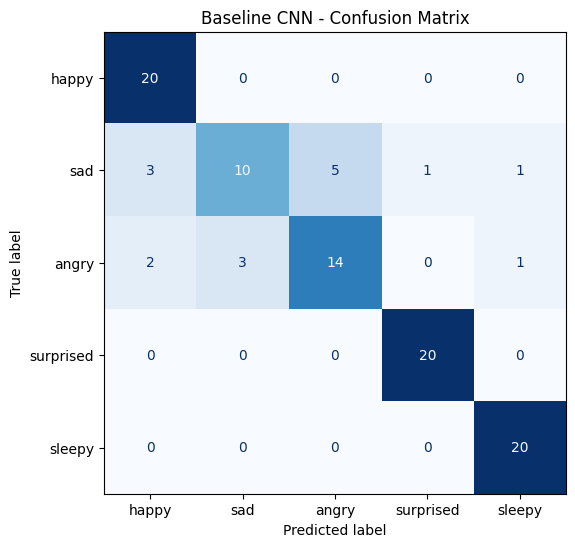

In [12]:
@torch.no_grad()
def predict_loader(model, loader, device):
    model.eval()
    all_probs, all_preds, all_targets = [], [], []

    for images, targets in loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1)

        all_probs.append(probs.cpu())
        all_preds.append(preds.cpu())
        all_targets.append(targets)

    all_probs = torch.cat(all_probs).numpy()
    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()
    return all_probs, all_preds, all_targets

# TODO
baseline_probs, baseline_preds, test_targets = predict_loader(baseline_model, test_loader, device)

baseline_acc = accuracy_score(test_targets, baseline_preds)
baseline_prec, baseline_rec, baseline_f1, _ = precision_recall_fscore_support(test_targets, baseline_preds, average='macro')

print(f"Baseline Test Accuracy : {baseline_acc:.4f}")
print(f"Baseline Test Precision: {baseline_prec:.4f}")
print(f"Baseline Test Recall   : {baseline_rec:.4f}")
print(f"Baseline Test F1-score : {baseline_f1:.4f}")

print("\nClassification report:")
print(classification_report(test_targets, baseline_preds, target_names=CLASS_NAMES))

cm = confusion_matrix(test_targets, baseline_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Baseline CNN - Confusion Matrix")
plt.show()

## بخش ۱۰ — تحلیل خطاها

### صورت سؤال
1. چند نمونه از تصاویر اشتباه‌طبقه‌بندی‌شده را نمایش دهید.
2. برای هر نمونه، برچسب واقعی و برچسب پیش‌بینی‌شده را بنویسید.
3. تلاش کنید برای خطاها توضیح بصری بدهید؛ مثلاً:
   - چرخش زیاد
   - نویز
   - شباهت بین mouth patternها
   - occlusion

### خروجی مورد انتظار
- چند تصویر misclassified
- تحلیل کیفی

Number of mistakes: 16 / 100


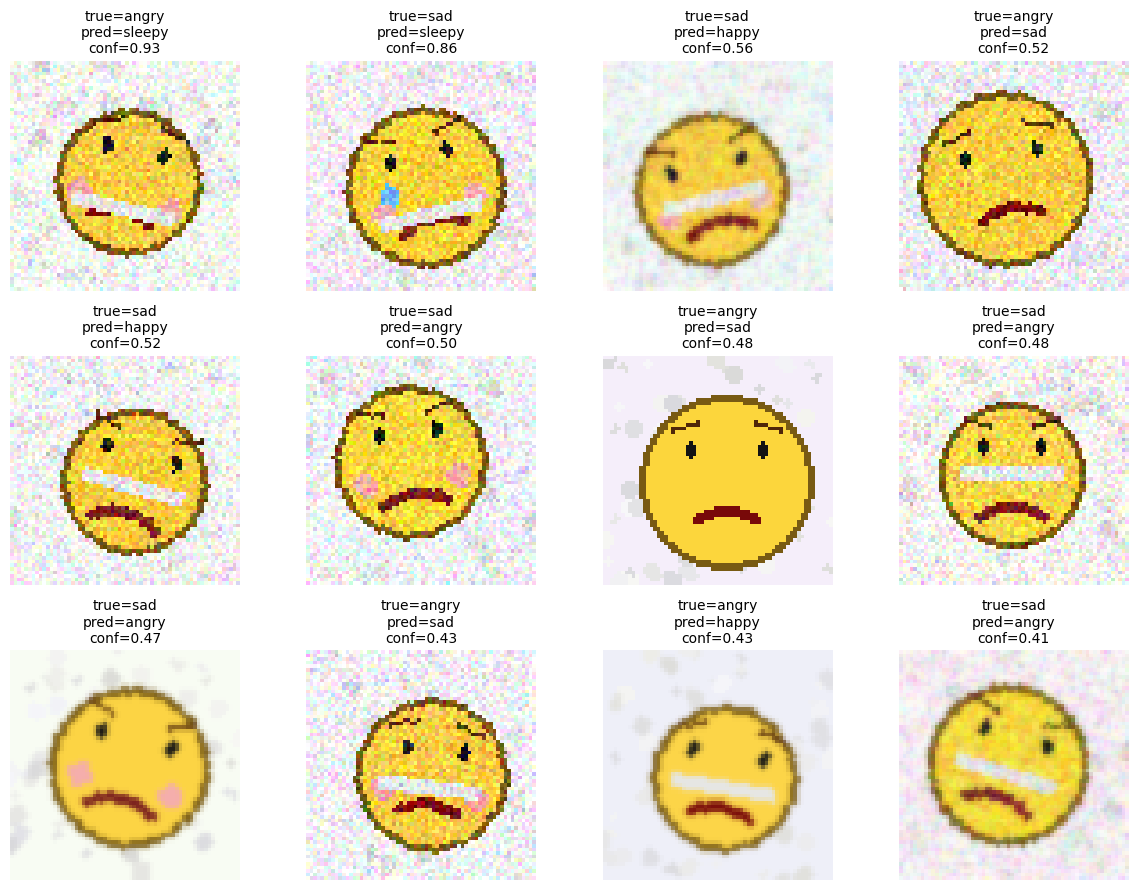

In [13]:
@torch.no_grad()
def collect_predictions_with_images(model, dataset, device, max_items=None):
    model.eval()
    items = []
    total = len(dataset) if max_items is None else min(len(dataset), max_items)

    for idx in range(total):
        # TODO
        image, label = dataset[idx]
        image_batch = image.unsqueeze(0).to(device)
        outputs = model(image_batch)
        probs = torch.softmax(outputs, dim=1)
        pred = outputs.argmax(dim=1).item()
        
        items.append({
            "image": image,
            "label": label,
            "pred": pred,
            "confidence": float(probs[0, pred].item()),
        })
    return items

# TODO
test_items = collect_predictions_with_images(baseline_model, test_dataset, device)
mistakes = [item for item in test_items if item["label"] != item["pred"]]
mistakes = sorted(mistakes, key=lambda x: x["confidence"], reverse=True)

print(f"Number of mistakes: {len(mistakes)} / {len(test_items)}")

n_show = min(12, len(mistakes))
if n_show > 0:
    cols = 4
    rows = math.ceil(n_show / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
    axes = np.array(axes).reshape(rows, cols)

    for ax in axes.ravel():
        ax.axis("off")

    for i in range(n_show):
        item = mistakes[i]
        img = np.transpose(denormalize(item["image"]).numpy(), (1, 2, 0))
        ax = axes.ravel()[i]
        ax.imshow(img)
        ax.set_title(
            f"true={CLASS_NAMES[item['label']]}\npred={CLASS_NAMES[item['pred']]}\nconf={item['confidence']:.2f}",
            fontsize=10
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Great! No mistakes found in the displayed set.")

*تحلیل کیفی که شما از نتایج مشاهده کردید:*

Most of the errors are between visually similar classes. The largest confusion is sad → angry, which is expected because both classes have open eyes and a downward mouth, and their main difference is the eyebrow direction. This difference can become difficult to detect under noise, rotation, blur, or occlusion. Some happy samples are also classified as sleepy, probably because both classes may contain curved or closed-looking eyes. Overall, the errors suggest that the model has learned the main facial patterns, but it is still sensitive to small local features such as eyebrows and mouth shape.

## بخش ۱۱ — مشاهده‌ی feature mapها

### صورت سؤال
برای یکی از تصاویر تست:
1. خروجی اولین بلوک کانولوشنی را استخراج کنید.
2. چند feature map را نمایش دهید.
3. توضیح دهید که این feature mapها احتمالاً چه نوع الگوهایی را شکار می‌کنند.

### خروجی مورد انتظار
- تصویر ورودی
- چند feature map

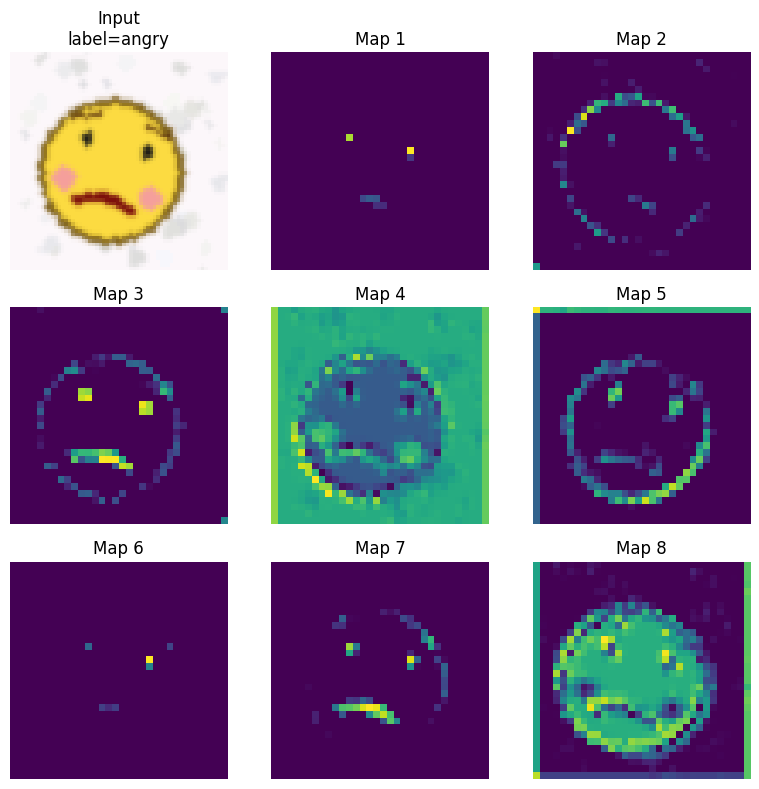

In [14]:
@torch.no_grad()
def show_feature_maps(model, dataset, sample_idx=0, n_maps=8):
    model.eval()
    image, label = dataset[sample_idx]
    x = image.unsqueeze(0).to(device)

    # TODO:
    first_block = model.block1
    fmap = first_block(x).squeeze(0).cpu()

    fig, axes = plt.subplots(3, 3, figsize=(8, 8))
    axes = axes.ravel()

    axes[0].imshow(np.transpose(denormalize(image).numpy(), (1, 2, 0)))
    axes[0].set_title(f"Input\nlabel={CLASS_NAMES[label]}")
    axes[0].axis("off")

    for i in range(1, min(n_maps + 1, 9)):
        axes[i].imshow(fmap[i - 1], cmap="viridis")
        axes[i].set_title(f"Map {i}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

show_feature_maps(baseline_model, test_dataset, sample_idx=3, n_maps=8)

The first convolutional block seems to extract low-level visual patterns such as edges, dark regions, face boundaries, and parts of the eyes or mouth. Some feature maps respond strongly to the outline of the emoji face, while others highlight local facial components such as the mouth or eyes. This is expected because early CNN layers usually learn simple visual features, and deeper layers combine them into more semantic patterns useful for classification.

## بخش ۱۲ — مدل بهبود‌یافته

### صورت سؤال
اکنون یک مدل بهتر طراحی کنید که نسبت به مدل پایه، **پایدارتر** و **قابل‌تعمیم‌تر** باشد.

### پیشنهادها
- استفاده از `BatchNorm`
- استفاده از `AdaptiveAvgPool2d`
- استفاده از dropout بیشتر
- عمیق‌تر کردن مدل
- استفاده از optimizer و weight decay مناسب

### کارهای لازم
1. مدل جدید را پیاده‌سازی کنید.
2. آن را آموزش دهید.
3. عملکردش را با مدل پایه مقایسه کنید.

### خروجی مورد انتظار
- تعریف مدل جدید
- لاگ آموزش
- مقایسه‌ی metricها

In [15]:
class BetterCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        # TODO
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        
        self.fc = nn.Sequential(
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        # TODO
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

better_model = BetterCNN(NUM_CLASSES).to(device)
print(better_model)
print(f"Trainable params: {count_trainable_params(better_model):,}")

BetterCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block4): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Ba

Epoch 01 | train_loss=1.6240 train_acc=0.1767 | val_loss=1.6094 val_acc=0.2125
Epoch 02 | train_loss=1.6017 train_acc=0.2233 | val_loss=1.6059 val_acc=0.2000
Epoch 03 | train_loss=1.5494 train_acc=0.2767 | val_loss=1.5966 val_acc=0.2000
Epoch 04 | train_loss=1.4620 train_acc=0.4067 | val_loss=1.5619 val_acc=0.2125
Epoch 05 | train_loss=1.3090 train_acc=0.4267 | val_loss=1.5394 val_acc=0.2625
Epoch 06 | train_loss=1.1853 train_acc=0.4833 | val_loss=1.5674 val_acc=0.2375
Epoch 07 | train_loss=0.9906 train_acc=0.5800 | val_loss=2.3284 val_acc=0.2000
Epoch 08 | train_loss=0.8921 train_acc=0.6200 | val_loss=1.7898 val_acc=0.3375
Epoch 09 | train_loss=0.7626 train_acc=0.6567 | val_loss=0.8024 val_acc=0.5875
Epoch 10 | train_loss=0.6635 train_acc=0.6833 | val_loss=2.5443 val_acc=0.3125


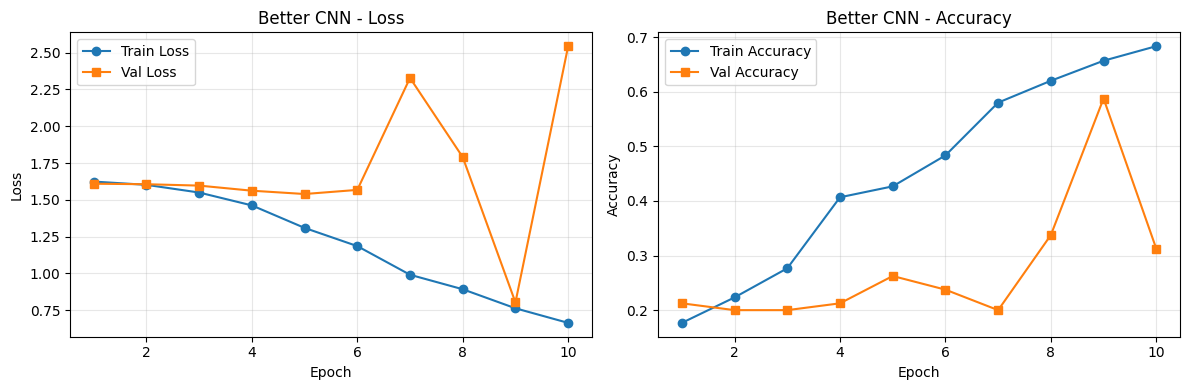

In [16]:
# TODO
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(better_model.parameters(), lr=0.001, weight_decay=1e-5)

better_history = fit_model(
    better_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=10,
    patience=4,
)

plot_history(better_history, title_prefix="Better CNN")

,model,accuracy,precision_macro,recall_macro,f1_macro,params
0,BaselineCNN,0.84,0.833509,0.84,0.828178,2191941
1,BetterCNN,0.53,0.397297,0.53,0.431078,653573


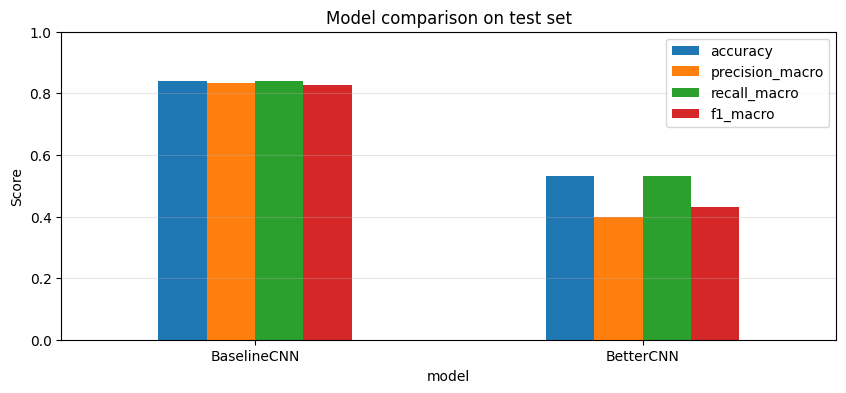

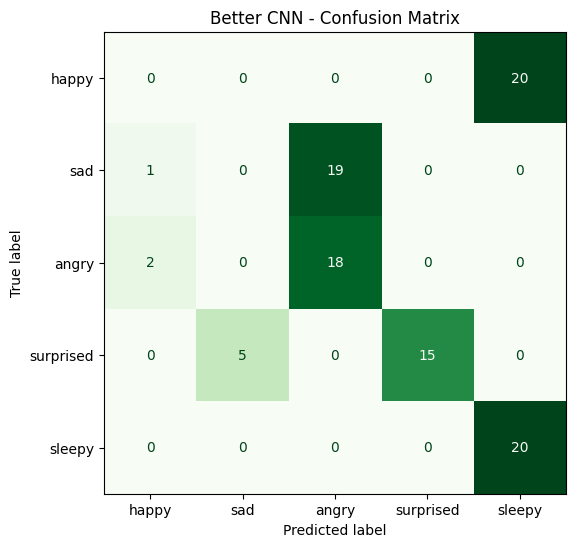

In [17]:
# TODO
better_probs, better_preds, _ = predict_loader(better_model, test_loader, device)

# TODO
better_acc = accuracy_score(test_targets, better_preds)
better_prec, better_rec, better_f1, _ = precision_recall_fscore_support(test_targets, better_preds, average='macro')

comparison_df = pd.DataFrame([
    {
        "model": "BaselineCNN",
        "accuracy": baseline_acc,
        "precision_macro": baseline_prec,
        "recall_macro": baseline_rec,
        "f1_macro": baseline_f1,
        "params": count_trainable_params(baseline_model),
    },
    {
        "model": "BetterCNN",
        "accuracy": better_acc,
        "precision_macro": better_prec,
        "recall_macro": better_rec,
        "f1_macro": better_f1,
        "params": count_trainable_params(better_model),
    },
])

display(comparison_df)

comparison_df.set_index("model")[["accuracy", "precision_macro", "recall_macro", "f1_macro"]].plot(
    kind="bar", figsize=(10, 4)
)
plt.ylim(0, 1.0)
plt.ylabel("Score")
plt.title("Model comparison on test set")
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.show()

cm_better = confusion_matrix(test_targets, better_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_better, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Greens", values_format="d", colorbar=False)
plt.title("Better CNN - Confusion Matrix")
plt.show()

## بخش ۱۳ — جمع‌بندی و پرسش‌های تحلیلی

### صورت سؤال
به پرسش‌های زیر پاسخ دهید:

1. آیا augmentation باعث بهتر شدن عملکرد مدل شد؟ چرا؟
2. کدام کلاس‌ها بیشتر با هم اشتباه شدند؟ دلیل بصری آن چیست؟
3. بین مدل پایه و مدل بهتر، کدام تغییرات بیشترین اثر را داشتند؟
4. آیا افزایش تعداد پارامترها همیشه به بهبود نتیجه منجر شد؟
5. اگر بخواهید این پروژه را سخت‌تر کنید، چه تغییری می‌دهید؟

### چند ایده برای بخش امتیازی
- ساخت یک **harder test set** با occlusion شدیدتر
- مقایسه‌ی optimizerهای `Adam` و `RMSprop`
- اضافه کردن **label smoothing**
- پیاده‌سازی **Grad-CAM** برای توضیح تصمیم مدل
- تبدیل مسئله از 5 کلاس به 7 کلاس با اضافه کردن `cool` و `confused`



1. 
Yes, augmentation likely improved the model’s generalization. The training images are synthetically generated, but the test set is harder because it may contain more noise, rotation, blur, and partial occlusion. Augmentation exposes the model during training to similar variations such as small rotations, crops, flips, and color changes. As a result, the model becomes less dependent on exact pixel positions or exact colors and learns more robust visual patterns such as the shape of the eyes, mouth, eyebrows, tears, or sleep bubbles.

2. The most natural confusion is usually between sad and angry, because both classes can have open eyes and a downward mouth. Their main difference is often the eyebrow direction, which is a small local feature and can be affected by rotation, blur, or noise. Some confusion can also happen between happy and sleepy if the model focuses too much on curved eye shapes, or between surprised and other classes if the mouth region is occluded. These mistakes are natural because the dataset contains small images and the class-defining features are sometimes subtle.

3. 
The most effective improvements were increasing the representational capacity of the CNN, using more stable convolutional blocks, and adding regularization properly. A deeper or better-designed CNN can learn more complex hierarchical features: early layers detect edges and simple shapes, while deeper layers combine them into eyes, mouths, eyebrows, and full facial expressions. Batch normalization helps stabilize training, and dropout reduces overfitting. If the better model also used global average pooling or a better classifier head, that likely reduced the number of fully connected parameters and improved generalization.

4. 
If training accuracy is high but validation accuracy is clearly lower, and training loss keeps decreasing while validation loss stops improving or increases, then the model is overfitting. This means the model has learned the training distribution too specifically and does not generalize perfectly to validation or hard test images. If both training and validation accuracy are low, then the model is underfitting. In this experiment, if the validation curves are close to the training curves and both improve steadily, the model is not strongly overfitting. If the gap becomes large near the end, early stopping and dropout are useful to control overfitting.

5. 
I would make the test set harder by adding stronger occlusion, blur, random rotations, and more background noise. I would also make class differences more subtle, especially between sad and angry, by reducing obvious features such as tears or strong eyebrow shapes. Another way is to reduce the training set size or introduce more variation in face position, scale, and color. This would force the model to learn more robust semantic features instead of relying on simple shortcuts.